<a href="https://colab.research.google.com/github/rinivarg/ReproRehab2024-Pod3/blob/main/Materials/Week%206/Week%206%20-%20Codebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6: Text Analysis in R
In previous weeks, we worked mainly with numeric data. This week, we turn to a kind of data that is everywhere in rehab research but much messier: **text**!

Clinical notes, discharge summaries, and patient-reported outcomes all contain rich information, but computers can't analyze raw text the way they analyze numbers. We first need to **clean** the text and **transform** it into a structured table. Only then can we look for meaningful patterns. This is the first step toward AI and machine learning techniques like natural language processing (NLP).

The text analysis pipeline has three key steps. By the end of this session, you will be able to:

| Part | Step | What you'll do |
| :---: | :--- | :--- |
| **A** | ***Load&nbsp;notes*** | Load and peek at the toy clinical notes text data; see if basic quality checks hold up. |
| **B** | ***Preprocessing*** | Clean and standardize strings using `stringr` and regular expressions (case, punctuation, patterns), and remove stop words. |
| **C** | ***Tokenize&nbsp;and&nbsp;count*** | Split text into tokens (e.g., words) and organize them into a structured table of counts, either by a pre-defined set of words (a **dictionary**) or by context. |
| **D** | ***Analyze&nbsp;patterns*** | Use word counts to explore patterns, such as frequent terms or differences between groups, and understand how deterministic pipelines (`stringr`, `tidytext`) differ from probabilistic ones (`udpipe`). |

<br>
<div style="float: center; margin-center: 5px;">
<img src = ./imgs/text_nlp.png alt="text analysis pipeline for clinical rehab notes" width="840" height="440">
<br>
<div style="text-align: right;"><small>Inspired by <a href="https://www.nature.com/articles/s44159-024-00392-z" target="_blank">Feuerriegel et al., 2025, Nature Reviews Psychology</a> and made with Claude (Anthropic)</small></div>
</div>

## Clear the entire workspace

In [9]:
rm(list = ls())

## Load required libraries
| Package | What we use it for |
| :--- | :--- |
| `dplyr`, `tidyr` | Data wrangling (same as previous weeks) |
| `stringr` | Working with text strings and regular expressions |
| `ggplot2` | Plotting (Week 4!) |
| `tidytext` | Splitting text into words (tokens) and stop words |

The first lines install any package you don't have yet.

In [10]:
ReqdLibs <- c("dplyr", "tidyr", "stringr", "ggplot2", "tidytext","patchwork")
invisible(lapply(ReqdLibs, library, character.only = TRUE))

## Theme defaults
Same idea as Week 4: define the theme once, then add `+ thm` to every plot.

In [11]:
thm = theme_minimal() +
      theme(
          strip.text.x = element_text(size = 18, face = "bold"),
          legend.text  = element_text(size = 14, face = "bold"),
          legend.title = element_text(size = 14, face = "bold"),
          legend.position = "top",
          text       = element_text(colour = "black", size = 16),
          plot.title = element_text(colour = "black", size = 20, face = "bold"),
          axis.line  = element_line(colour = "black", linewidth = 0.85),
          axis.ticks = element_line(colour = "black", linewidth = 0.85),
          axis.text  = element_text(colour = "black", size = 16),
          axis.title = element_text(size = 18))

options(repr.plot.width = 12, repr.plot.height = 7)

## A. Load Notes
Our data are **43 synthetic physical therapy notes** (no real patients!) from 10 patients:
* 5 patients after a **total knee replacement** (TKA)
* 5 patients after a **stroke** (CVA)

Each patient was seen for 4 visits. The file is a regular `.csv`, so we read it exactly like in Week 4.

| Column | Meaning |
| :--- | :--- |
| `note_id` | Row number of the note |
| `patient_id` | Fake patient ID (P01 – P10) |
| `visit` | Visit number (1 = evaluation, 4 = discharge) |
| `condition` | Diagnosis group, typed by the clinician |
| `note_text` | The free-text clinical note |


In [12]:
data_file <- "rehab_notes.csv"
notes_raw <- read.csv(data_file, fileEncoding = "UTF-8") %>% as_tibble()

head(notes_raw)

note_id,patient_id,visit,condition,note_text
<int>,<chr>,<int>,<chr>,<chr>
1,P01,1,Knee,"PT Initial Eval 03/02/2026. MRN: 302918. Pt s/p R TKA 10 days ago. c/o knee pain 7/10 &amp; swelling. AROM 5-75°. Amb 50 ft w/ RW, WBAT. Pt tolerated tx well. Will cont w/ POC. -- J. Patel, PT, DPT"
2,P01,2,TKA,"pt reports Pain: 5/10 today, less swelling. Knee ROM 0-90°. amb 150 ft w/ RW. Denies dizzyness. HEP reviewed. Pt tolerated tx well. Will cont w/ POC."
3,P01,3,Knee,Pt seen 3/16/26. Pain 4 out of 10 after stairs. Swelling mild. Amb 300' w/ SPC. Pt’s goal is to return to golf!! Pt tolerated tx well. Will cont w/ POC.
4,P01,4,knee,Discharge 2026-03-30. pain 2/10. AROM 0-115°. amb 500 ft w/o device; stairs reciprocal w/ rail. Indep w/ HEP. Electronically signed by M. Rivera PT
5,P02,1,TKA,"PT eval 03/04/2026 MRN#551207. Pt s/p L TKA. c/o severe knee pain 8/10, STIFFNESS & swelling. AROM 10-65°. Amb 40ft w/ RW, min A. Call (410) 555-0188 w/ questions. Pt tolerated tx well. Will cont w/ POC."
6,P02,2,TKA,"Pt reports pain=6/10, poor sleep d/t knee pain. swelling unchanged. Amb 100 ft w/ RW, CGA. Ice &amp; elevation reviewed. Pt tolerated tx well. Will cont w/ POC. -- J. Patel, PT, DPT"


**Notice:** 43 rows, but we said 10 patients × 4 visits = 40 notes. Something is already off. Keep that in mind.

### Read a note the way a computer sees it
`print()` shows the string exactly as R stores it (note the `\n`, which is a hidden *line break*). `writeLines()` shows it the way a human would see it on screen.

In [13]:
print(notes_raw$note_text[1])

[1] "PT Initial Eval 03/02/2026. MRN: 302918. Pt s/p R TKA 10 days ago. c/o knee pain 7/10 &amp; swelling. AROM 5-75°. Amb 50 ft w/ RW, WBAT. Pt tolerated tx well. Will cont w/ POC.\n-- J. Patel, PT, DPT"


In [14]:
writeLines(notes_raw$note_text[1])

PT Initial Eval 03/02/2026. MRN: 302918. Pt s/p R TKA 10 days ago. c/o knee pain 7/10 &amp; swelling. AROM 5-75°. Amb 50 ft w/ RW, WBAT. Pt tolerated tx well. Will cont w/ POC.
-- J. Patel, PT, DPT


**Notice:** In this one note there's a date, a medical record number (MRN), a clinician's name, lots of abbreviations (`Pt`, `s/p`, `c/o`, `RW`...), an HTML leftover (`&amp;`), and a degree symbol (`°`). A word counter would treat all of these as "words".

### Spot all the problems
Let's look at a handful more notes. Read them as a clinician first, then as a computer.

In [15]:
writeLines(notes_raw$note_text[c(2, 5, 23, 40)])

pt reports Pain: 5/10 today, less swelling. Knee ROM 0-90°. amb 150 ft w/ RW. Denies dizzyness. HEP reviewed. Pt tolerated tx well. Will cont w/ POC.
PT eval 03/04/2026 MRN#551207. Pt s/p L TKA. c/o severe knee pain 8/10, STIFFNESS & swelling. AROM 10-65°. Amb 40ft w/ RW, min A. Call (410) 555-0188 w/ questions. Pt tolerated tx well. Will cont w/ POC.
pt reports fatigeu after breakfast. Amb 40 ft w/ RW, min A. Balance improving. Denies pain. Pt tolerated tx well. Will cont w/ POC.
-- M. Rivera, PT
pt reports FATIGUE
and difficulty sleeping. Amb 35 ft w/ RW, min A. Balance training in parallel bars. Pt tolerated tx well. Will cont w/ POC.


<br>
Here is every problem planted in this dataset, and where we fix it:


| # | Problem | Example from the notes | 
| :-: | :--- | :--- | 
| 1 | Empty or missing notes | `"   "`, `NA` 
| 2 | Duplicate (copy-pasted) notes | note 14 = note 15 | A.4 |
| 3 | Inconsistent group labels | `Knee`, `knee `, `TKA` / `Stroke`, `CVA` | A.5 |
| 4 | Identifiers (must remove!) | `MRN#551207`, `(410) 555-0188`, `3/16/26`, `-- J. Patel, PT` | C.1 |
| 5 | Numbers hidden inside text | `pain 7/10`, `pain 4 out of 10`, `Amb 300'` | C.2 |
| 6 | Encoding junk & spacing | `&amp;`, curly `’`, `40ft`, line breaks, double spaces | C.3 |
| 7 | Abbreviations | `Pt` (patient) vs `PT` (physical therapy), `w/`, `w/o`, `min A` | C.4 |
| 8 | Inconsistent case | `FATIGUE`, `Fatigue`, `fatigue` | C.5 |
| 9 | Misspellings | `fatigeu`, `fatique`, `balence`, `dizzyness` | C.5 |
| 10 | Negation | `Denies pain` contains the word "pain" | C.6 |
| 11 | Punctuation, numbers, symbols | `!!`, `??`, `5-75°` | C.7 |
| 12 | Boilerplate template text | `Pt tolerated tx well. Will cont w/ POC.` | D.3 |

### Fix the rows: missing, empty, and duplicate notes
Before touching the *text*, clean the *table* with `dplyr` tools you already know:
* `is.na()` catches true missing values. But a note that is only spaces `"   "` is **not** `NA`, so we also use `str_squish()`, which removes extra whitespace and turns a blank note into `""`.
* `distinct()` keeps only the first copy of rows that are identical in the columns we list.

In [16]:
notes <- notes_raw %>%
  filter(!is.na(note_text), str_squish(note_text) != "") %>%
  distinct(patient_id, visit, note_text, .keep_all = TRUE)

nrow(notes)   # now it should be 40

[1] 40

### Fix the group labels
Clinicians typed the diagnosis in different ways. To R, `"Knee"`, `"knee "` (with a trailing space!) and `"TKA"` are three different groups.

In [17]:
notes %>% count(condition)

condition,n
<chr>,<int>
CVA,7
Knee,10
Stroke,9
TKA,6
knee,4
stroke,4


Let's first **standardize** (remove spaces, lowercase), then **recode** with `case_when()` from Week 4.<br>
**Notice:** 6 messy labels became 2 clean groups of 20 notes each.

In [18]:
notes <- notes %>%
  mutate(condition = str_squish(str_to_lower(condition)),
         condition = case_when(condition %in% c("knee", "tka")   ~ "Knee",
                               condition %in% c("stroke", "cva") ~ "Stroke"))

notes %>% count(condition)

condition,n
<chr>,<int>
Knee,20
Stroke,20


## B. Preprocessing
A **regular expression (regex)** is a mini-language for describing *patterns* in text, like a super-powered Ctrl+F. Instead of searching for `"03/14/2026"`, we can search for "two digits, a slash, two digits, a slash, four digits", which finds *every* date.

The five `stringr` functions we'll use
All `stringr` functions start with `str_` and take **(the text, the pattern)** in that order.

| Function | Question it answers | Returns |
| :--- | :--- | :--- |
| `str_detect(x, pattern)` | *Is* the pattern there? | `TRUE` / `FALSE` |
| `str_count(x, pattern)` | *How many times* is it there? | a number |
| `str_extract(x, pattern)` | *What* matched (first match)? | the matched text |
| `str_replace_all(x, pattern, new)` | Replace every match with something else | edited text |
| `str_remove_all(x, pattern)` | Delete every match | edited text |

Let's practice on a single note.

In [19]:
x <- notes$note_text[5]
writeLines(x)

PT eval 03/04/2026 MRN#551207. Pt s/p L TKA. c/o severe knee pain 8/10, STIFFNESS & swelling. AROM 10-65°. Amb 40ft w/ RW, min A. Call (410) 555-0188 w/ questions. Pt tolerated tx well. Will cont w/ POC.


In [20]:
str_detect(x, "walker")     # is "walker" in the note?
str_detect(x, "RW")         # is "RW" (rolling walker) in the note?

[1] FALSE

[1] TRUE

**Notice:** `"walker"` is `FALSE` because the clinician wrote `RW`. A search is only as good as what we tell it to look for. This is why we will expand abbreviations later.

In [21]:
str_count(x, "pain")        # how many times does "pain" appear?
str_count(x, "Pt")          # how many times does "Pt" appear?

[1] 1

[1] 2

### Understanding the regex "cipher"
Literal words get us only so far. These special symbols describe *kinds* of characters. These are the ones we use today:

> ⚠️ In R, a backslash must be typed **twice**: the regex `\d` is written `"\\d"` in R code.

| Symbol | Meaning | Example pattern | Matches |
| :---: | :--- | :--- | :--- |
| `\\d` | any digit 0–9 | `"\\d"` | `7` |
| `+` | one **or more** of the previous thing | `"\\d+"` | `302918` |
| `{n}` / `{n,m}` | exactly n / between n and m | `"\\d{4}"` | `2026` |
| `\\s` | any whitespace (space, tab, line break) | `"\\s*"` | `""`, `" "`, `"   "` |
| `*` | zero or more of the previous thing | `"\\s*"` | (optional spaces) |
| `\\b` | a word **boundary** (edge of a word) | `"\\bpain\\b"` | `pain` but not `painful` |
| `[ ]` | **one** of these characters | `"[Pp]t"` | `Pt` or `pt` |
| `[^ ]` | **anything except** these characters | `"[^a-z]"` | `7`, `!`, `°` |
| `\|` | OR | `"ft\|feet"` | `ft` or `feet` |
| `( )` | group things together (and "capture" them) | `"(\\d+) ft"` | `40 ft`, captures `40` |

#### (i) Digits and repetition: `\\d`, `+`, `{n}`

In [22]:
str_extract(x, "\\d")              # one digit
str_extract(x, "\\d+")             # one or more digits in a row
str_extract(x, "\\d{2}/\\d{2}/\\d{4}")   # a date: 2 digits / 2 digits / 4 digits

[1] "0"

[1] "03"

[1] "03/04/2026"

**Notice:** `str_extract()` returns only the **first** match. The last line finds a date by describing its *shape*.

#### (ii) Word boundaries `\\b`: the most important symbol today
Without `\\b`, a pattern can match *inside* another word.

In [23]:
demo <- "Pt tolerated therapy; the other patient did not."

str_remove_all(demo, "the")          # mangles "therapy" and "other"!
str_remove_all(demo, "\\bthe\\b")    # removes only the whole word "the"

[1] "Pt tolerated rapy;  or patient did not."

[1] "Pt tolerated therapy;  other patient did not."

#### (iii) OR `|` and groups `( )`
`|` means "this or that". Parentheses `( )` group parts of a pattern and let us **capture** a piece of the match with `str_match()`.

In [24]:
y <- c("Amb 50 ft", "Amb 40ft", "Amb 300'", "walked 20 feet")

str_extract(y, "\\d+\\s*(ft|feet|')")     # whole match: number + unit
str_match(y, "(\\d+)\\s*(ft|feet|')")     # column 1 = whole match, column 2 = first ( ), column 3 = second ( )

[1] "50 ft"   "40ft"    "300'"    "20 feet"

50 ft,50,ft
40ft,40,ft
300',300,'
20 feet,20,feet


**Notice:** `\\s*` ("zero or more spaces") handles both `50 ft` and `40ft`. Column 2 of `str_match()` gives us just the number, which we'll use in Part C.

#### (iv) Using a regex on the whole data frame
Every `str_` function works on a whole column, so they fit right inside `filter()` and `mutate()`.

In [25]:
# which notes mention fatigue?
notes %>%
  filter(str_detect(note_text, "fatigue")) %>%
  select(note_id, condition, note_text)

note_id,condition,note_text
<int>,<chr>,<chr>
19,Knee,"Pt reports pain 5 out of 10, poor sleep. Swelling mild. Amb 150 ft w/ RW, mild fatigue. HEP updated. Pt tolerated tx well. Will cont w/ POC."
25,Stroke,"Amb 150 ft w/ SPC, supervision. Stairs w/ rail, CGA. Reports less fatigue &amp; improved confidence. Family training completed 2026-03-31. Electronically signed by M. Rivera PT"
26,Stroke,"PT eval 03/05/2026 MRN#551988. Pt s/p R CVA. c/o L shoulder pain 4/10 &amp; fatigue. Amb 25 ft w/ RW, min A. Impaired balance w/ standing. Pt tolerated tx well. Will cont w/ POC."
35,Stroke,"PT eval 03/10/2026. MRN: 721004. Pt s/p R CVA. L LE weakness, impaired balance. c/o fatigue &amp; poor sleep. Amb 30 ft w/ RW, min A. Pt tolerated tx well. Will cont w/ POC."
36,Stroke,"Pt reports improved balance!! Amb 60 ft w/ RW, CGA. Mild fatigue after tx. Denies pain or dizziness. Pt tolerated tx well. Will cont w/ POC."
39,Stroke,"PT Initial Eval 03/11/2026. MRN#448210. Pt s/p L CVA. R UE &amp; LE weakness, c/o fatigue &amp; dizziness. Amb 20 ft w/ RW, mod A. Pt tolerated tx well. Will cont w/ POC."
43,Stroke,"Amb 150 ft w/ SPC, supervision. Reports less fatigue. Denies pain. Pt anxious about stairs at home. Call (443) 555-0129 to schedule f/u. -- M. Rivera, PT"


In [26]:
# same question, ignoring case
notes %>%
  filter(str_detect(note_text, regex("fatigue", ignore_case = TRUE))) %>%
  nrow()

[1] 13

**Notice:** Case-sensitive search finds only some of the fatigue notes; ignoring case finds more. And there are still misspellings like `fatigeu` hiding! We'll catch those in Part C.

> Regex is **deterministic**: the same pattern on the same text gives the same answer every time, and you can always read *why* something matched. That makes it transparent, but it only finds what you thought to ask for.

### Using `regex` to define and extract patterns
Now we fix the text, **one problem at a time**. Each step creates a **new column**, so we can always compare before and after:

`note_text` → `text_deid` → `text_fixed` → `text_expanded` → `text_lower` → `text_neg` → `text_clean`

> **IMPORTANT: Order matters!** Three rules of thumb:
> 1. **De-identify first**, so identifiers never leak into later steps.
> 2. **Extract numbers before you delete them** (numbers get removed in the last step).
> 3. **Do case-sensitive steps before lowercasing** (`PT` ≠ `Pt`).

First, a small helper function so we can watch one note change through every stage.

In [27]:
# prints selected columns of one note, one per line
show_note <- function(data, id, cols) {
  row <- data %>% filter(note_id == id)
  for (col in cols) cat(sprintf("%-14s| %s\n", col, row[[col]]))
}

notes_clean <- notes     # we'll add new columns to this copy

#### (i) De-identify
Clinical notes contain **protected health information (PHI)**. We remove four kinds, each written in more than one format:

| Identifier | Formats in our notes | Pattern idea |
| :--- | :--- | :--- |
| MRN | `MRN: 302918`, `MRN#551207`, `mrn 774120` | "mrn", optional `:` or `#`, digits (ignore case) |
| Phone | `410-555-0142`, `(410) 555-0188`, `410.555.0177` | 3 digits, 3 digits, 4 digits, with optional `( )`, `-`, `.` |
| Date | `03/02/2026`, `3/16/26`, `2026-03-30` | two date shapes joined by `\|` |
| Signature | `-- J. Patel, PT, DPT`, `Electronically signed by M. Rivera PT` | from `--` or "Electronically signed by" to the end `$` |

> ⚠️ Real de-identification needs far more care than four regexes (names, addresses, ages > 89...). Always follow your IRB and data-use agreement.

Let's write and test each pattern **before** using it.

In [28]:
mrn_pattern   <- regex("mrn\\s*[:#]?\\s*\\d+", ignore_case = TRUE)
phone_pattern <- "\\(?\\d{3}\\)?[-. ]?\\d{3}[-.]\\d{4}"
date_pattern  <- "\\d{1,2}/\\d{1,2}/\\d{2,4}|\\d{4}-\\d{2}-\\d{2}"
sig_pattern   <- "(--|Electronically signed by).*$"

# test: what does each pattern find across all notes?
str_extract(notes$note_text, mrn_pattern)   %>% na.omit() %>% unique()
str_extract(notes$note_text, phone_pattern) %>% na.omit() %>% unique()
str_extract(notes$note_text, date_pattern)  %>% na.omit() %>% unique()
str_extract(notes$note_text, sig_pattern)   %>% na.omit() %>% unique()

[1] "MRN: 302918" "MRN#551207"  "mrn 774120"  "MRN: 610455" "MRN#829301" 
 [6] "MRN: 483920" "MRN#551988"  "mrn 390112"  "MRN: 721004" "MRN#448210"

[1] "(410) 555-0188" "410.555.0177"   "410-555-0142"   "(443) 555-0129"

[1] "03/02/2026" "3/16/26"    "2026-03-30" "03/04/2026" "3/27/26"   
 [6] "2026-03-05" "3/31/26"    "03/06/2026" "2026-04-01" "03/09/2026"
[11] "4/2/26"     "03/03/2026" "3/17/26"    "2026-03-31" "03/05/2026"
[16] "4/1/26"     "2026-03-04" "3/18/26"    "03/10/2026" "2026-04-03"
[21] "03/11/2026" "3/25/26"

[1] "-- J. Patel, PT, DPT"                 
[2] "Electronically signed by M. Rivera PT"
[3] "-- M. Rivera, PT"

**Notice:** Every format in the table above is found, and nothing else (no pain scores or range-of-motion numbers sneak in). Now remove them:

In [29]:
notes_clean <- notes_clean %>%
  mutate(text_deid = note_text %>%
           str_remove_all(mrn_pattern) %>%
           str_remove_all(phone_pattern) %>%
           str_remove_all(date_pattern) %>%
           str_remove_all(sig_pattern))

show_note(notes_clean, 1, c("note_text", "text_deid"))

note_text     | PT Initial Eval 03/02/2026. MRN: 302918. Pt s/p R TKA 10 days ago. c/o knee pain 7/10 &amp; swelling. AROM 5-75°. Amb 50 ft w/ RW, WBAT. Pt tolerated tx well. Will cont w/ POC.
-- J. Patel, PT, DPT
text_deid     | PT Initial Eval . . Pt s/p R TKA 10 days ago. c/o knee pain 7/10 &amp; swelling. AROM 5-75°. Amb 50 ft w/ RW, WBAT. Pt tolerated tx well. Will cont w/ POC.



#### (ii) Extract numbers into real variables
Our notes hide two outcome measures inside text: **pain scores** and **walking distance**. Regex can pull them out into numeric columns, so text becomes data you can plot and test like Weeks 1–5.

**Pain score (0–10)**
Clinicians wrote it many ways: `7/10`, `Pain: 5/10`, `pain=6/10`, `NPRS 5/10`, `4 out of 10`. They also wrote *strength* grades like `3/5`, which we must **not** grab.

Pattern: `(\\d{1,2})\\s*(/|out of)\\s*10\\b` = "a 1–2 digit number (captured), then `/` or `out of`, then 10"

In [30]:
pain_pattern <- "(\\d{1,2})\\s*(/|out of)\\s*10\\b"

# test on the different ways pain was written
test <- c("pain 7/10", "Pain: 5/10", "pain=6/10", "NPRS 5/10", "Pain 4 out of 10", "Quad strenght 3/5")
str_match(test, pain_pattern)

7/10,7,/
5/10,5,/
6/10,6,/
5/10,5,/
4 out of 10,4,out of
NA,NA,NA


**Notice:** Every pain format gives a number in column 2, and the strength grade `3/5` gives `NA`.

##### IMPT!! Why we de-identified first: a real bug
What if we extracted pain from the **original** text instead?

In [31]:
notes_clean %>%
  mutate(pain_from_raw  = str_match(note_text, pain_pattern)[, 2],
         pain_from_deid = str_match(text_deid, pain_pattern)[, 2]) %>%
  filter(note_id == 35) %>%
  select(note_text, pain_from_raw, pain_from_deid)

note_text,pain_from_raw,pain_from_deid
<chr>,<chr>,<chr>
"PT eval 03/10/2026. MRN: 721004. Pt s/p R CVA. L LE weakness, impaired balance. c/o fatigue &amp; poor sleep. Amb 30 ft w/ RW, min A. Pt tolerated tx well. Will cont w/ POC.",03,NA


**Notice:** Note 35 has **no pain score**, but the raw-text version reports pain = 03! The date `03/10/2026` looks like "3 out of 10". Removing dates first prevents this. *Order matters.*

Now create the real columns from `text_deid`:

In [32]:
dist_pattern <- "(\\d+)\\s*(ft|feet|')"

notes_clean <- notes_clean %>%
  mutate(pain_score  = as.numeric(str_match(text_deid, pain_pattern)[, 2]),
         distance_ft = as.numeric(str_match(text_deid, dist_pattern)[, 2]))

notes_clean %>% select(note_id, patient_id, visit, condition, pain_score, distance_ft) %>% head(10)

note_id,patient_id,visit,condition,pain_score,distance_ft
<int>,<chr>,<int>,<chr>,<dbl>,<dbl>
1,P01,1,Knee,7,50
2,P01,2,Knee,5,150
3,P01,3,Knee,4,300
4,P01,4,Knee,2,500
5,P02,1,Knee,8,40
6,P02,2,Knee,6,100
7,P02,3,Knee,5,250
8,P02,4,Knee,3,400
9,P03,1,Knee,6,60


##### Plot! Hoorah!
These columns are now ordinary numeric data. Let's plot recovery over visits.
We now have quantified information from text! 

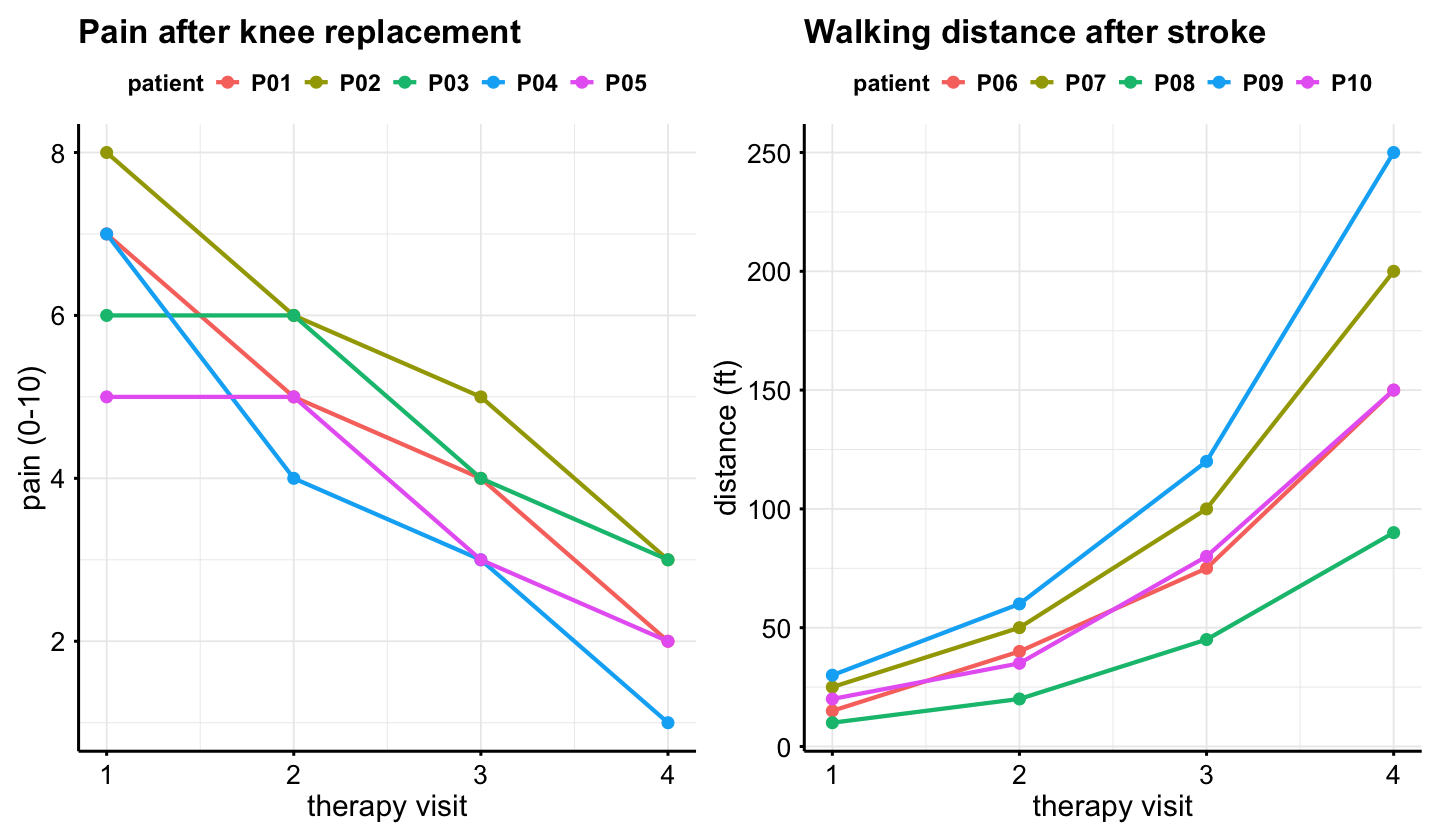

In [33]:
pain_TKR_plot = 
notes_clean %>%
  filter(condition == "Knee") %>%
  ggplot(aes(x = visit, y = pain_score, colour = patient_id)) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 3) +
  labs(title = "Pain after knee replacement", x = "therapy visit", y = "pain (0-10)", colour = "patient") +
  thm

walkDist_stroke_plot = 
notes_clean %>%
  filter(condition == "Stroke") %>%
  ggplot(aes(x = visit, y = distance_ft, colour = patient_id)) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 3) +
  labs(title = "Walking distance after stroke", x = "therapy visit", y = "distance (ft)", colour = "patient") +
  thm

pain_TKR_plot | walkDist_stroke_plot

#### (iii) Fix encoding junk and spacing
Text copied between systems picks up "invisible" problems:

| Problem | Example | Fix |
| :--- | :--- | :--- |
| HTML entity | `&amp;` | replace with ` and ` (**before** fixing plain `&`!) |
| Plain ampersand | `&` | replace with ` and ` |
| Curly apostrophe | `Pt’s` (not the same character as `Pt's`!) | replace `’` with `'` |
| Possessive `'s` | `Pt's` | remove `'s` |
| Number glued to a word | `40ft` | add a space: `40 ft` |
| Line breaks, double spaces | `"FATIGUE\nand"`, `"Swelling   decreased"` | `str_squish()` |

In the next cell, `"(\\d)([A-Za-z])"` captures a digit and the letter right after it; in the replacement, `"\\1 \\2"` puts the two captured pieces back **with a space in between**.

In [34]:
notes_clean <- notes_clean %>%
  mutate(text_fixed = text_deid %>%
           str_replace_all("&amp;", " and ") %>%
           str_replace_all("&", " and ") %>%
           str_replace_all("’", "'") %>%
           str_remove_all("'s\\b") %>%
           str_replace_all("(\\d)([A-Za-z])", "\\1 \\2") %>%
           str_squish())

show_note(notes_clean, 40, c("text_deid", "text_fixed"))

text_deid     | pt reports FATIGUE
and difficulty sleeping. Amb 35 ft w/ RW, min A. Balance training in parallel bars. Pt tolerated tx well. Will cont w/ POC.
text_fixed    | pt reports FATIGUE and difficulty sleeping. Amb 35 ft w/ RW, min A. Balance training in parallel bars. Pt tolerated tx well. Will cont w/ POC.


**Notice:** the line break inside "FATIGUE / and" is gone and the spacing is even. (Try `show_note(notes_clean, 5, ...)` for `40ft` and `&`.)

> **Question:** Why must `&amp;` be replaced *before* `&`? (Hint: what would `&amp;` become otherwise?)

#### (iv) Expand abbreviations
Clinical shorthand is everywhere. If we don't expand it, `RW` and `rolling walker` count as different words, and `Pt` (patient) and `PT` (physical therapy) get confused.

We use a **named vector**: `"pattern" = "replacement"`. `str_replace_all()` applies the pairs **in order, top to bottom**, which lets us control tricky cases:

| Order trap | Why this order |
| :--- | :--- |
| `PT` before `[Pp]t` | `PT` is case-sensitive, so this must run **before lowercasing** |
| `w/o` before `w/` | otherwise `w/o` becomes "with o" |
| `min A` before `min` | `min A` = minimal assist; plain `min` = minutes |

In [35]:
# manually define abbreviations and their expansions
abbrev <- c(
  "\\bPT\\b"       = "physical therapy",
  "\\b[Pp]t\\b"    = "patient",
  "\\b[Ee]val\\b"  = "evaluation",
  "\\bc/o\\b"      = "complains of",
  "\\bs/p\\b"      = "status post",
  "\\bd/t\\b"      = "due to",
  "\\bd/c\\b"      = "discharge",
  "\\bf/u\\b"      = "follow up",
  "\\bw/o\\b"      = "without",
  "\\bw/"          = "with ",
  "\\bTKA\\b"      = "total knee arthroplasty",
  "\\bCVA\\b"      = "stroke",
  "\\bAROM\\b"     = "active range of motion",
  "\\bROM\\b"      = "range of motion",
  "\\bWBAT\\b"     = "weight bearing as tolerated",
  "\\bNPRS\\b"     = "pain rating",
  "\\bHEP\\b"      = "home exercise program",
  "\\bRW\\b"       = "rolling walker",
  "\\bSPC\\b"      = "single point cane",
  "\\bCGA\\b"      = "contact guard assist",
  "\\bmin A\\b"    = "minimal assist",
  "\\bmod A\\b"    = "moderate assist",
  "\\bmin\\b"      = "minutes",
  "\\bSOB\\b"      = "shortness of breath",
  "\\bUE\\b"       = "upper extremity",
  "\\bLE\\b"       = "lower extremity",
  "\\bR\\b"        = "right",
  "\\bL\\b"        = "left",
  "\\bAM\\b"       = "morning",
  "\\b[Aa]mb\\b"   = "ambulated",
  "\\b[Ii]ndep\\b" = "independent",
  "\\b[Qq]uad\\b"  = "quadriceps",
  "\\btx\\b"       = "treatment",
  "\\bcont\\b"     = "continue",
  "\\bPOC\\b"      = "plan of care",
  "\\bft\\b"       = "feet"
)
# write them into a dataframe and save them as CSV
abbrev_df = data.frame(pattern = names(abbrev), replacement = abbrev)
head(abbrev_df)

# write.csv(abbrev_df, "abbreviations.csv", row.names = FALSE, fileEncoding = "UTF-8")

,pattern,replacement
,<chr>,<chr>
\bPT\b,\bPT\b,physical therapy
\b[Pp]t\b,\b[Pp]t\b,patient
\b[Ee]val\b,\b[Ee]val\b,evaluation
\bc/o\b,\bc/o\b,complains of
\bs/p\b,\bs/p\b,status post
\bd/t\b,\bd/t\b,due to


In [36]:
# read the CSV file in (you may already have this file instead of manually defining them)
abbrev_table <- read.csv("abbreviations.csv", fileEncoding = "UTF-8")
abbrev <- setNames(abbrev_table$replacement, abbrev_table$pattern)
notes_clean <- notes_clean %>%
  mutate(text_expanded = str_squish(str_replace_all(text_fixed, abbrev)))

show_note(notes_clean, 5, c("text_fixed", "text_expanded"))

text_fixed    | PT eval . Pt s/p L TKA. c/o severe knee pain 8/10, STIFFNESS and swelling. AROM 10-65°. Amb 40 ft w/ RW, min A. Call w/ questions. Pt tolerated tx well. Will cont w/ POC.
text_expanded | physical therapy evaluation . patient status post left total knee arthroplasty. complains of severe knee pain 8/10, STIFFNESS and swelling. active range of motion 10-65°. ambulated 40 feet with rolling walker, minimal assist. Call with questions. patient tolerated treatment well. Will continue with plan of care.


**Notice:** `PT eval` → "physical therapy evaluation", `Pt` → "patient", `w/ RW, min A` → "with rolling walker, minimal assist". The note is now readable by someone (or something) that doesn't know rehab shorthand.

> **Question:** Look at the list. Which abbreviation could mean something *else* in a different clinic? (e.g., `SOB`, `R`, `L`, `AM`.) Abbreviation lists are **local knowledge** and must be checked for every new dataset.

#### (v) Lowercase and fix misspellings
Now that case-sensitive steps are done, we can lowercase everything, so `FATIGUE`, `Fatigue` and `fatigue` become one word. Then a small spelling dictionary fixes the typos (same named-vector trick).

In [37]:
spelling <- c(
  "\\bfatigeu\\b"   = "fatigue",
  "\\bfatique\\b"   = "fatigue",
  "\\bdizzyness\\b" = "dizziness",
  "\\bbalence\\b"   = "balance",
  "\\bstrenght\\b"  = "strength"
)

notes_clean <- notes_clean %>%
  mutate(text_lower = text_expanded %>%
           str_to_lower() %>%
           str_replace_all(spelling))

How much did this matter? Count notes that mention fatigue at each stage:

In [38]:
notes_clean %>%  
  summarise(original_text     = sum(str_detect(note_text,  "fatigue")),
            after_lower_spell = sum(str_detect(text_lower, "fatigue")))

original_text,after_lower_spell
<int>,<int>
7,15


**Notice:** More than double the fatigue notes are found after this step. Without cleaning, we would badly *undercount* a key symptom.

#### (vi) Handle negation
`"Denies pain"` contains the word *pain*, but means the **opposite**. A word counter can't tell the difference. A simple rule: glue the negation word to the next word, so `denies pain` → `no_pain`, a separate token.

Pattern: `\\b(denies|no|without)\\s+(\\w+)` captures the negation word (group 1) and the next word (group 2). The replacement `"no_\\2"` keeps only group 2 with `no_` in front.

In [39]:
neg_pattern <- "\\b(denies|no|without)\\s+(\\w+)"

notes_clean <- notes_clean %>%
  mutate(text_neg = str_replace_all(text_lower, neg_pattern, "no_\\2"))

# show every negation we created
str_extract_all(notes_clean$text_neg, "no_\\w+") %>% unlist() %>% table()

.
   no_device no_dizziness    no_nausea      no_pain  no_swelling 
           5            4            1            5            1 

**Notice:** `denies dizziness or nausea` → `no_dizziness or nausea`. Our rule only negates the **next** word, so *nausea* is still counted as present. That's a wrong answer from a deterministic rule.

> Every rule is a simplification. Good text analysis checks where the rules fail and reports it. More advanced tools (like `negex`-style algorithms or the models in Part F) handle negation better.

#### (vii) Remove numbers, punctuation and symbols
Finally, keep **only** lowercase letters, underscores (for our `no_` tokens) and spaces. `[^a-z_\\s]` means "any character that is *not* a letter, `_`, or whitespace". We replace those with a space (so `re-evaluated` doesn't become `reevaluated`) and then squish.

In [40]:
notes_clean <- notes_clean %>%
  mutate(text_clean = text_neg %>%
           str_replace_all("[^a-z_\\s]", " ") %>%
           str_squish())

show_note(notes_clean, 1, c("note_text", "text_clean"))

note_text     | PT Initial Eval 03/02/2026. MRN: 302918. Pt s/p R TKA 10 days ago. c/o knee pain 7/10 &amp; swelling. AROM 5-75°. Amb 50 ft w/ RW, WBAT. Pt tolerated tx well. Will cont w/ POC.
-- J. Patel, PT, DPT
text_clean    | physical therapy initial evaluation patient status post right total knee arthroplasty days ago complains of knee pain and swelling active range of motion ambulated feet with rolling walker weight bearing as tolerated patient tolerated treatment well will continue with plan of care


### Putting it all together!

In [41]:
show_note(notes_clean, 23,
          c("note_text", "text_deid", "text_fixed", "text_expanded", "text_lower", "text_neg", "text_clean"))

note_text     | pt reports fatigeu after breakfast. Amb 40 ft w/ RW, min A. Balance improving. Denies pain. Pt tolerated tx well. Will cont w/ POC.
-- M. Rivera, PT
text_deid     | pt reports fatigeu after breakfast. Amb 40 ft w/ RW, min A. Balance improving. Denies pain. Pt tolerated tx well. Will cont w/ POC.

text_fixed    | pt reports fatigeu after breakfast. Amb 40 ft w/ RW, min A. Balance improving. Denies pain. Pt tolerated tx well. Will cont w/ POC.
text_expanded | patient reports fatigeu after breakfast. ambulated 40 feet with rolling walker, minimal assist. Balance improving. Denies pain. patient tolerated treatment well. Will continue with plan of care.
text_lower    | patient reports fatigue after breakfast. ambulated 40 feet with rolling walker, minimal assist. balance improving. denies pain. patient tolerated treatment well. will continue with plan of care.
text_neg      | patient reports fatigue after breakfast. ambulated 40 feet with rolling walker, minimal assist. bala

> Never trust a pipeline you haven't checked. Read a few notes at every stage, and search for anything that shouldn't be there (try `str_detect(notes_clean$text_clean, "\\d|mrn")`).

## C. Tokenize and Count
Our text is clean, but it's still one long string per note. To count, we split it into **tokens**.

### Tokenization: one row per word
A **token** is the unit of analysis: usually a word (could also be a sentence, or a pair of words). `unnest_tokens(new_column, text_column)` turns *one row per note* into *one row per word*, keeping the other columns (`note_id`, `condition`...) on every row.

In [42]:
tokens <- notes_clean %>%
  select(note_id, patient_id, visit, condition, text_clean) %>%
  unnest_tokens(word, text_clean)

nrow(notes_clean)   # rows = notes
nrow(tokens)        # rows = words
head(tokens, 10)

[1] 40

[1] 1144

note_id,patient_id,visit,condition,word
<int>,<chr>,<int>,<chr>,<chr>
1,P01,1,Knee,physical
1,P01,1,Knee,therapy
1,P01,1,Knee,initial
1,P01,1,Knee,evaluation
1,P01,1,Knee,patient
1,P01,1,Knee,status
1,P01,1,Knee,post
1,P01,1,Knee,right
1,P01,1,Knee,total


**Notice:** `no_pain` and `no_dizziness` stay as single tokens, because `_` counts as part of a word.

> `unnest_tokens()` also lowercases and drops punctuation by default, so part of Part C was "redundant". That's on purpose: now you know what happens under the hood, and you control the decisions (like negation) that it can't make for you.

### Stop words
**Stop words** are very common words (*the, with, of, and*) that carry little meaning. `tidytext` comes with a list called `stop_words`. We remove them with `anti_join()`: "keep the rows in `tokens` that do **not** have a match in `stop_words`".

In [43]:
head(stop_words)
nrow(stop_words)

word,lexicon
<chr>,<chr>
a,SMART
a's,SMART
able,SMART
about,SMART
above,SMART
according,SMART


[1] 1149

In [44]:
tokens_clean <- tokens %>% anti_join(stop_words, by = "word")

nrow(tokens)          # before
nrow(tokens_clean)    # after

[1] 1144

[1] 858

In [45]:
word_counts <- tokens_clean %>% count(word, sort = TRUE)
head(word_counts, 15)

word,n
<chr>,<int>
patient,66
ambulated,40
feet,35
plan,33
tolerated,31
treatment,31
care,30
continue,30
pain,24


### Other cleaning
Sometimes, cleaning reveals a new problem
> **💬 Discuss:** Look at the top words. Do *tolerated, treatment, continue, plan, care* tell us anything about these patients?

They come from the **template sentence** `"Pt tolerated tx well. Will cont w/ POC."` pasted into most notes. Let's check:

In [46]:
boilerplate <- "patient tolerated treatment well will continue with plan of care"

sum(str_detect(notes_clean$text_clean, boilerplate))   # how many notes contain it?

[1] 30

Real text cleaning is **iterative**: you count, you notice something, you go back and fix it. We remove the template phrase, and also add a few **domain stop words**: words that appear in nearly every note and so can't tell notes apart (*patient, reports...*).

In [47]:
notes_clean <- notes_clean %>%
  mutate(text_clean = str_squish(str_remove_all(text_clean, boilerplate)))

custom_stops <- tibble(word = c("patient", "reports", "seen", "physical", "therapy",
                                "evaluation", "initial", "status", "post", "complains"))

tokens_clean <- notes_clean %>%
  select(note_id, patient_id, visit, condition, text_clean) %>%
  unnest_tokens(word, text_clean) %>%
  anti_join(stop_words,   by = "word") %>%
  anti_join(custom_stops, by = "word")

word_counts <- tokens_clean %>% count(word, sort = TRUE)
head(word_counts, 15)

word,n
<chr>,<int>
ambulated,40
feet,35
pain,24
walker,24
rolling,22
assist,20
fatigue,15
knee,12
motion,12


**Notice:** The top words are now clinical (e.g., *ambulated, pain, walker, fatigue, swelling, stairs*), not template filler.

> Stop word lists are **choices**, not facts. "no" is a standard stop word, which is exactly why we turned `no pain` into `no_pain` *before* this step. Removing stop words first would have erased every negation.

## D. Analyze Patterns
Now the text is structured data, and everything from previous weeks applies.

### (i) Most frequent words by group
`reorder_within()` + `scale_y_reorder()` (from `tidytext`) sort the bars correctly **inside each facet**. Plain `reorder()` can't do that across facets.

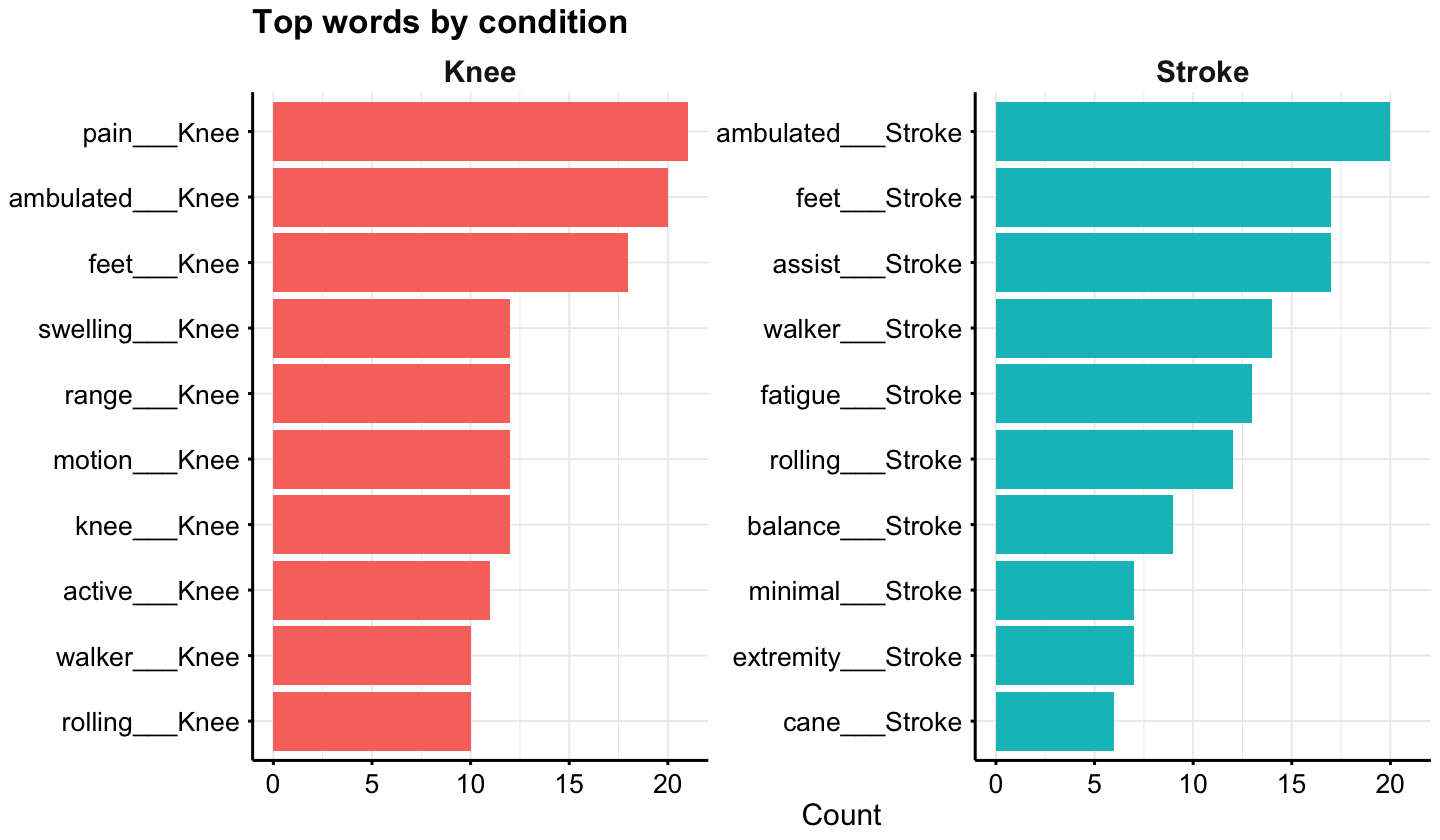

In [48]:
group_counts <- tokens_clean %>% count(condition, word)

group_counts %>%
  group_by(condition) %>%
  slice_max(n, n = 10, with_ties = FALSE) %>%
  ungroup() %>%
  ggplot(aes(x = n, y = reorder_within(word, n, condition), fill = condition)) +
  geom_col(show.legend = FALSE) +
  facet_wrap(~ condition, scales = "free_y") +
  # scale_y_reorder() +
  labs(title = "Top words by condition", x = "Count", y = NULL) +
  thm

**Notice:** Knee notes talk about *knee, swelling, pain*; stroke notes about *fatigue* and *balance*. Words like *ambulated* appear in both groups, so they don't tell the groups apart.

### (ii) Back to statistics: text → variable → test
Any text feature can become a regular variable. Does the proportion of notes mentioning fatigue differ between groups? Two groups × yes/no = a 2×2 table, so we use **Fisher's exact test** (good for small counts).

In [49]:
notes_clean <- notes_clean %>%
  mutate(has_fatigue = str_detect(text_clean, "\\bfatigue\\b"))

table(notes_clean$condition, notes_clean$has_fatigue)
fisher.test(table(notes_clean$condition, notes_clean$has_fatigue))

        
         FALSE TRUE
  Knee      18    2
  Stroke     7   13


	Fisher's Exact Test for Count Data

data:  table(notes_clean$condition, notes_clean$has_fatigue)
p-value = 0.0007716
alternative hypothesis: true odds ratio is not equal to 1
95 percent confidence interval:
   2.538776 174.369649
sample estimates:
odds ratio 
  15.34457 


> ⚠️ **Caution:** 40 synthetic notes, and several come from the same patient (not independent!). This demonstrates the **workflow**, not a clinical finding. A real analysis would use one row per patient or a mixed model.

In [50]:
# compare: the same test on the UNCLEANED text (case-sensitive "fatigue" only)
notes_clean <- notes_clean %>% mutate(has_fatigue_raw = str_detect(note_text, "fatigue"))
table(notes_clean$condition, notes_clean$has_fatigue_raw)

        
         FALSE TRUE
  Knee      19    1
  Stroke    14    6

**Notice:** With uncleaned text, many stroke notes "lose" their fatigue mention (`FATIGUE`, `Fatigue`, `fatigeu`...). **Your cleaning choices change your statistical results.** This is why preprocessing must be reported and reproducible.

### (iii) Understanding Deterministic vs Probabilistic Text Analysis
Everything today was **deterministic**: we wrote every rule, and the same rule always gives the same result. But our rules don't know that *improved* and *improving* are the same word, or whether a word is a noun or a verb.

**Probabilistic** tools like `udpipe` use a **statistical model trained** on thousands of hand-annotated sentences. For each word, the model **predicts** its *lemma* (dictionary form: *improving, improved* → *improve*) and its *part of speech* (NOUN, VERB...).

| | Deterministic <br><small>`stringr`, `tidytext`</small> | Probabilistic <br><small>`udpipe`, `cleanNLP`, `text`</small> |
| :--- | :--- | :--- |
| Who makes the rules? | You write them | Model learned patterns from training data |
| Same input → same output? | Always | Output is a *prediction*; can be wrong |
| Transparency | Fast, easy to audit | Handles grammar/context, harder to audit |
| `walked` vs `walking`? | Different words | Same lemma: `walk` |
| Best for | Cleaning and counting | Grammar, context, foundation for modern NLP |

> Models trained on general English have never seen `Amb 50 ft w/ RW`. That's why the deterministic cleaning we did today (especially expanding abbreviations) comes **first**, even when you later use AI tools. The two approaches work best **together**.

## Additional Resources
1) *Text Mining with R* (tidytext book): https://www.tidytextmining.com
2) `stringr` regular expressions guide: https://stringr.tidyverse.org/articles/regular-expressions.html
3) *R for Data Science*, Regular expressions chapter: https://r4ds.hadley.nz/regexps.html
4) Interactive regex tester (paste a note and try patterns): https://regex101.com

<span style="color: #D80B77; font-size: 40px;">**Try it yourself!**</span>

1) **Plot it:** We already extracted `distance_ft` in C.2. Plot walking distance over visits for every patient, faceted by `condition` (Week 4!).
2) **Regex:** Range of motion was written like `AROM 5-75°`. Extract the **flexion** value (the second number, e.g. `75`) from `text_deid` into a numeric column `flexion_deg`.
   * Hint: `"(\\d+)-(\\d+)°"` and `str_match(...)[, 3]`
3) **Negation:** Count `"\\bpain\\b"` in `text_lower` (before negation) vs `text_clean` (after) for each group. How many "pain" mentions were actually denials?
4) **Statistics:** Replace `fatigue` in E.2 with `swelling` or `balance`. Does the group difference change?

# The End